### <i><b>Fast rigid rotational alignment of voxelized 3-D density maps in sliced Wasserstein distance  
</br>

#### This notebook contains several demonstrations of the code for FSW3D:

###### 1\) ICDF Transform
###### 2\) Sliced Wasserstein Distance
###### 3\) Rotational Alignment 
</br>

###### * for rotational alignment, you only need to load your data and run step 3
---

In [1]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt

### other
import mrcfile

### fsw3d
from fast_volume_align_ot import transforms, signals, distances, alignments, plots, utils

---

### 0) Load data


In [ ]:
### Load the data into numpy array
### Example here using simulated cryo-EM data

volume_1_file = 'Data/0.mrc'
volume_2_file = 'Data/49.mrc'

with mrcfile.open(volume_1_file, permissive=True) as mrc:
    f = mrc.data
    f_dx = mrc.voxel_size.x
    mrc.close()

with mrcfile.open(volume_2_file, permissive=True) as mrc:
    g = mrc.data
    g_dx = mrc.voxel_size.x
    mrc.close()

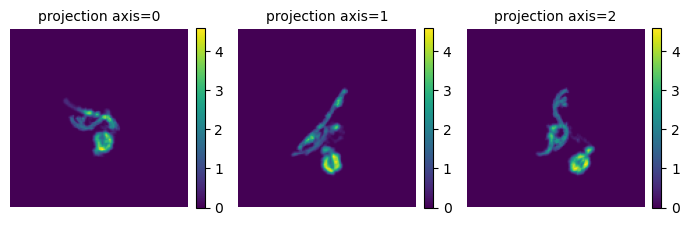

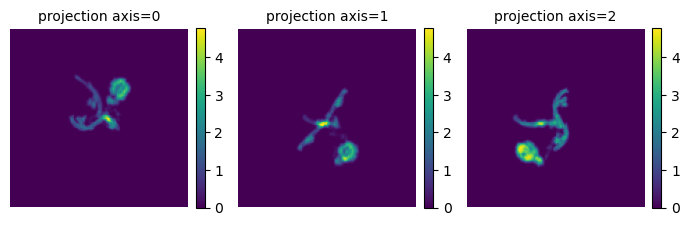

In [3]:
### Inspect the data

plots.orthogonal_2D_projection_plot(f)
plots.orthogonal_2D_projection_plot(g)

---

### 1) ICDF Transform


In [4]:
### Normalize the data and compute the transform grid
N = f.shape[0]  ### assumes equal dimension
grid = transforms.Grids(N=N)

f = signals.Signal(f, dx=f_dx, d=3).preprocess_signals()[0]

# ### Radon transform
# f_rt = transforms.Transform(f, d=3, grid).radon_transform()[0]
# ### Quantile tensor / ICDF transform
# f_t = transforms.Transform(f, d=3, grid).inverse_cdf_transform()[0]
### ramp-filtered version
f_tp, f_tn = transforms.Transform(f, d=3, grid=grid, apply_ramp=True).signed_inverse_cdf_transform()
f_tp, f_tn = f_tp[0], f_tn[0]

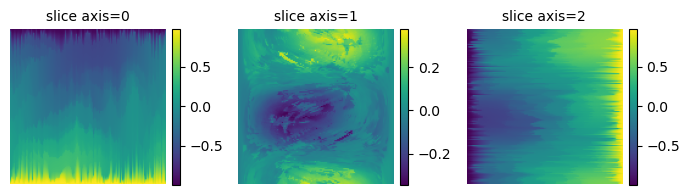

In [5]:
### Inspect the transfromed data

plots.orthogonal_2D_slice_plot(f_tp)

---

### 2) Sliced Wasserstein Distance

In [6]:
### Compute the 3-D sliced 2-Wasserstein distance between the transformed voxel arrays

f_tp, f_tn = transforms.Transform(f, d=3, grid=grid, apply_ramp=True).signed_inverse_cdf_transform()
f_tp, f_tn = f_tp[0], f_tn[0]

g_tp, g_tn = transforms.Transform(g, d=3, grid=grid, apply_ramp=True).signed_inverse_cdf_transform()
g_tp, g_tn = g_tp[0], g_tn[0]

d_rfsw_p = distances.compute_3d_sliced_wasserstein_distance(f_tp, g_tp, grid) / (4*np.pi)
d_rfsw_n = distances.compute_3d_sliced_wasserstein_distance(f_tn, g_tn, grid) / (4*np.pi)

d_rfsw = (d_rfsw_p + d_rfsw_n) / 2

print(d_rfsw)

0.028642472185373025


---

### 3) Rotational Alignment

In [ ]:
volume_1_file = 'Data/0.mrc'
volume_2_file = 'Data/49.mrc'

with mrcfile.open(volume_1_file, permissive=True) as mrc:
    f = mrc.data
    f_dx = mrc.voxel_size.x
    mrc.close()

with mrcfile.open(volume_2_file, permissive=True) as mrc:
    g = mrc.data
    g_dx = mrc.voxel_size.x
    mrc.close()

### Choose the metric you want to use
# metric = 'L2'
# metric = 'SW'
metric = 'RFSW'

### Compute alignment in ramp-filtered sliced 2-Wasserstein distance
t = time.time()
alignment_rfsw = alignments.Alignment(f, g, metric, normalize=True, apply_refinement=True, store_alignment=True)
print("alignment RFSW = ", time.time() - t)
print('\n')

### EV: you can also set store_alignment=False to store only the alignment matrix, not the aligned volume
###     the alignment matrix can be accessed as alignment_rfsw.R
###     to generate the aligned volume later, you need to run
# # o_est, b_est, a_est = transforms.rotmat_to_euler_zyz(R_est)[::-1]
# # g_aligned = transforms.rotate_voxel_zyz_fourier(g, -a_est, -b_est, -o_est)

print(alignment_rfsw.R)

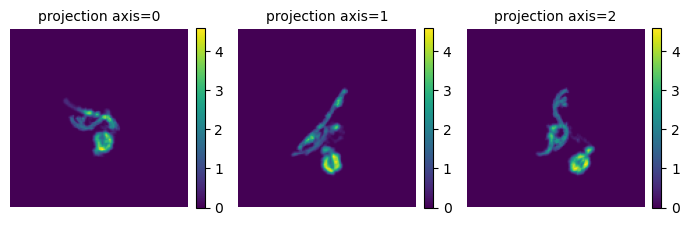

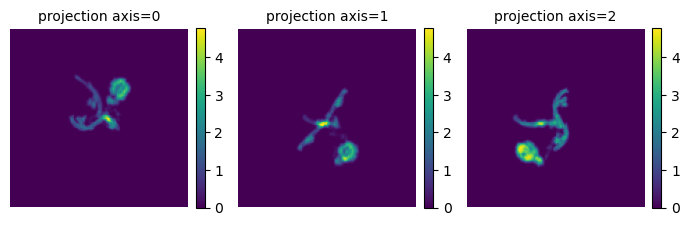

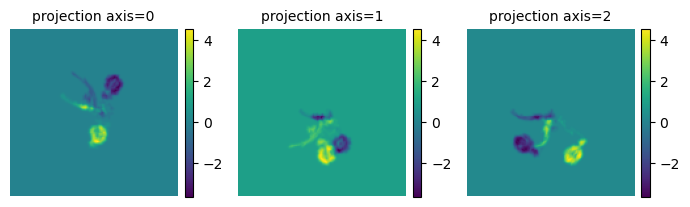

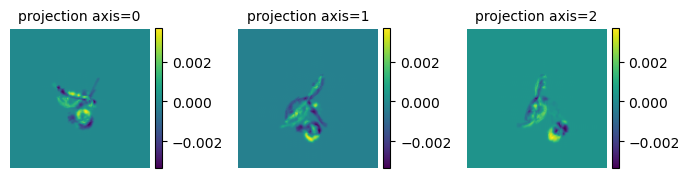

In [8]:
### Visualize the alignment result

### EV: here we need to first normalize f, because the aligned g has been normalized
f_normalized = signals.Signal(f, dx=f_dx, d=3).preprocess_signals()[0]
g_normalized_aligned = alignment_rfsw.aligned

plots.orthogonal_2D_projection_plot(f)
plots.orthogonal_2D_projection_plot(g)
plots.orthogonal_2D_projection_plot(f - g)
plots.orthogonal_2D_projection_plot(f_normalized - g_normalized_aligned)